# Desigualdades de Bell y CHSH — simulaciones reproducibles

**Proyecto de Mecánica Cuántica · Aylin Fernanda Terán Díaz**

Se simula el estado singlete, se contrasta con un modelo de variables ocultas locales y se estudian el tamaño de muestra, la visibilidad y las pérdidas de detección. Todas las gráficas se guardan en `../figuras/`. El muestreo cuántico usa las probabilidades de Born: **no es una prueba experimental independiente de Bell**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

SEED = 42
OUT = Path("../figuras")
DATA = Path("../datos")
OUT.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "axes.grid": True})
SQRT2 = np.sqrt(2)
angles = np.deg2rad([0, 90, 45, 135])
a, ap, b, bp = angles
settings = [(a,b), (a,bp), (ap,b), (ap,bp)]
def rng_for(section):
    # Generadores separados: los resultados no dependen del orden de ejecución de otras secciones.
    return np.random.default_rng(np.random.SeedSequence([SEED, section]))

## 1. Modelo cuántico y correlación angular

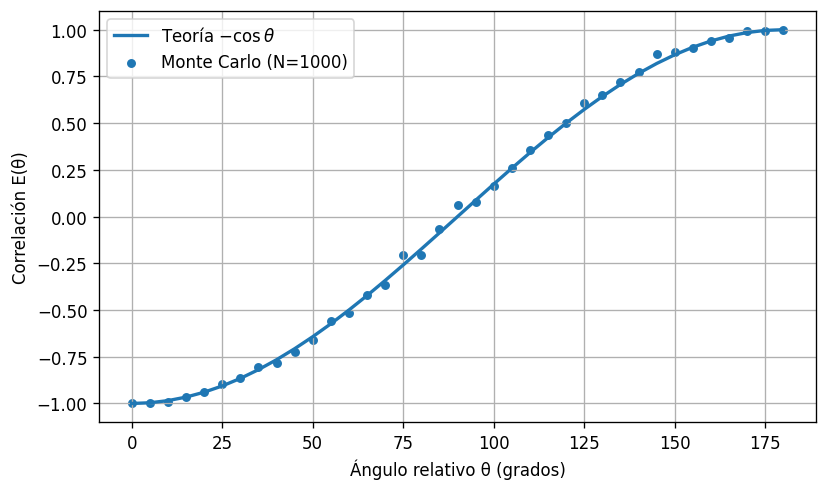

In [2]:
def quantum_products(theta, n, rng, visibility=1.0):
    # P(AB=-1|theta)=(1+V cos(theta))/2
    opposite = rng.random(n) < (1 + visibility*np.cos(theta))/2
    return np.where(opposite, -1, +1)

def quantum_chsh(n, rng, visibility=1.0):
    e = np.array([quantum_products(x-y,n,rng,visibility).mean() for x,y in settings])
    return e, e[0]-e[1]+e[2]+e[3]

theta = np.linspace(0, np.pi, 37)
rng = rng_for(1)
e_mc = np.array([quantum_products(t,1000,rng).mean() for t in theta])
fig, ax = plt.subplots(figsize=(7,4.2))
ax.plot(np.rad2deg(theta), -np.cos(theta), label=r"Teoría $-\cos\theta$", lw=2)
ax.scatter(np.rad2deg(theta),e_mc,label="Monte Carlo (N=1000)",s=19)
ax.set(xlabel="Ángulo relativo θ (grados)", ylabel="Correlación E(θ)", ylim=(-1.1,1.1))
ax.legend(); fig.tight_layout(); fig.savefig(OUT/"correlacion_angular.png"); plt.show()

## 2. CHSH: estimación y estadística finita

Correlaciones N=10000: [-0.7064  0.693  -0.7134 -0.7028]
S N=10000: -2.8156 ; |S|: 2.8156


,N,abs_S,error_absoluto
0,100,2.8400,0.011573
1,1000,2.8420,0.013573
2,10000,2.8300,0.001573
3,100000,2.8303,0.001873


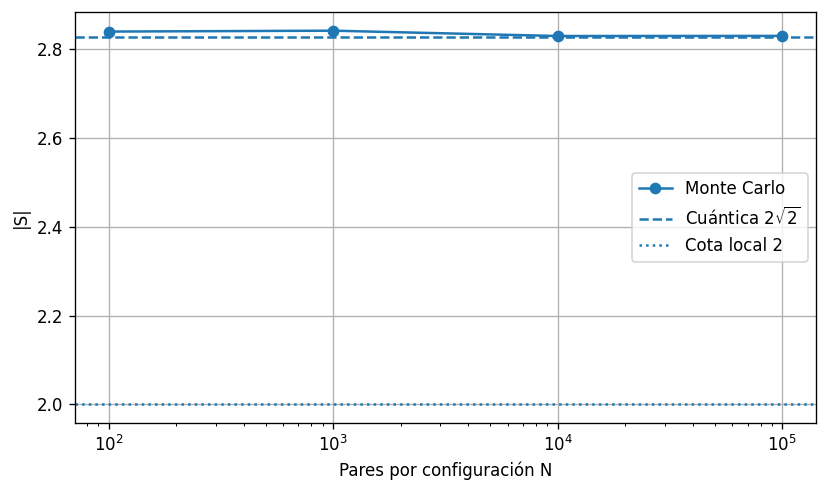

In [3]:
rng=rng_for(2)
e10k,s10k=quantum_chsh(10_000,rng)
print("Correlaciones N=10000:",e10k)
print("S N=10000:",s10k,"; |S|:",abs(s10k))
rng=rng_for(3)
sizes=[100,1000,10000,100000]
conv=[]
for n in sizes:
    e,s=quantum_chsh(n,rng)
    conv.append((n,abs(s),abs(abs(s)-2*SQRT2)))
df_conv=pd.DataFrame(conv,columns=["N","abs_S","error_absoluto"])
display(df_conv)
fig,ax=plt.subplots(figsize=(7,4.2))
ax.semilogx(df_conv.N,df_conv.abs_S,"o-",label="Monte Carlo")
ax.axhline(2*SQRT2,ls="--",label=r"Cuántica $2\sqrt{2}$")
ax.axhline(2,ls=":",label="Cota local 2")
ax.set(xlabel="Pares por configuración N",ylabel="|S|")
ax.legend();fig.tight_layout();fig.savefig(OUT/"convergencia_CHSH.png");plt.show()

## 3. Modelo de variables ocultas locales

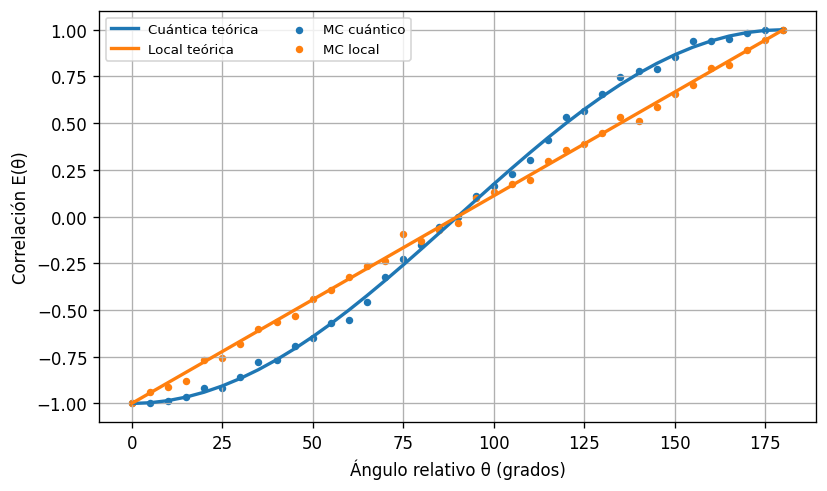

CHSH cuántico N=100000 [-0.70614  0.70828 -0.70784 -0.70772] -2.82998
CHSH local N=100000 [-0.49854  0.5014  -0.49942 -0.50084] -2.0001999999999995
SE: 0.004469676361885724 ; IC95% aproximado para |S|: (np.float64(2.821219434330704), np.float64(2.838740565669296))


In [4]:
def local_products(theta,n,rng):
    lam=rng.uniform(0,2*np.pi,n)
    A=np.where(np.cos(lam)>=0,1,-1)
    B=-np.where(np.cos(lam-theta)>=0,1,-1)
    return A*B

def local_chsh(n,rng):
    # Cada par de configuraciones comparte la misma ley de lambda.
    e=np.array([local_products(y-x,n,rng).mean() for x,y in settings])
    return e,e[0]-e[1]+e[2]+e[3]

rngq=rng_for(4); rngl=rng_for(5)
q=np.array([quantum_products(t,1000,rngq).mean() for t in theta])
l=np.array([local_products(t,1000,rngl).mean() for t in theta])
fig,ax=plt.subplots(figsize=(7,4.2))
ax.plot(np.rad2deg(theta),-np.cos(theta),label="Cuántica teórica",lw=2)
ax.plot(np.rad2deg(theta),-1+2*theta/np.pi,label="Local teórica",lw=2)
ax.scatter(np.rad2deg(theta),q,s=12,label="MC cuántico")
ax.scatter(np.rad2deg(theta),l,s=12,label="MC local")
ax.set(xlabel="Ángulo relativo θ (grados)",ylabel="Correlación E(θ)",ylim=(-1.1,1.1))
ax.legend(ncol=2,fontsize=8);fig.tight_layout()
fig.savefig(OUT/"comparacion_local_cuantica.png");plt.show()
eq,sq=quantum_chsh(100000,rng_for(6))
el,sl=local_chsh(100000,rng_for(7))
print("CHSH cuántico N=100000",eq,sq)
print("CHSH local N=100000",el,sl)
se=np.sqrt(np.sum((1-eq**2)/100000))
print("SE:",se,"; IC95% aproximado para |S|:",(abs(sq)-1.96*se,abs(sq)+1.96*se))

## 4. Visibilidad y ruido

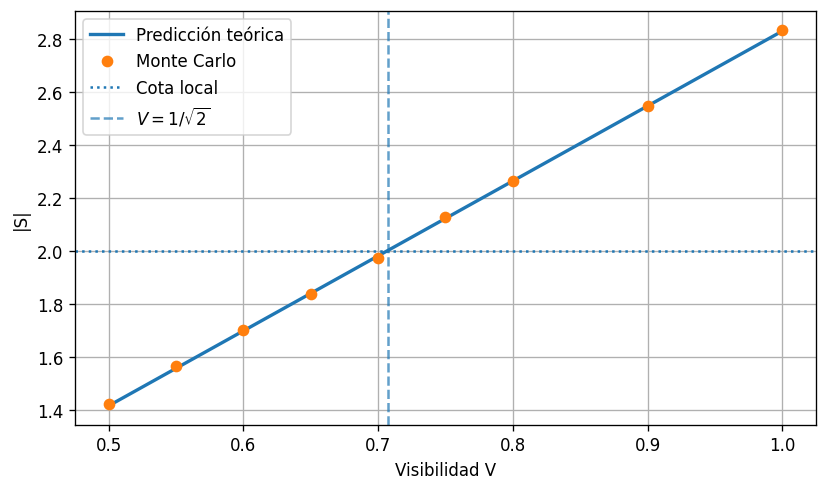

   V   abs_S
0.50 1.41948
0.55 1.56520
0.60 1.70202
0.65 1.83764
0.70 1.97348
0.75 2.12508
0.80 2.26420
0.90 2.54674
1.00 2.83316


In [5]:
vis=np.array([.50,.55,.60,.65,.70,.75,.80,.90,1.00])
rng=rng_for(8)
s_vis=np.array([abs(quantum_chsh(100000,rng,visibility=v)[1]) for v in vis])
fig,ax=plt.subplots(figsize=(7,4.2))
ax.plot(vis,2*SQRT2*vis,label="Predicción teórica",lw=2)
ax.plot(vis,s_vis,"o",label="Monte Carlo")
ax.axhline(2,ls=":",label="Cota local")
ax.axvline(1/SQRT2,ls="--",alpha=.7,label=r"$V=1/\sqrt{2}$")
ax.set(xlabel="Visibilidad V",ylabel="|S|")
ax.legend();fig.tight_layout();fig.savefig(OUT/"ruido_visibilidad_CHSH.png");plt.show()
print(pd.DataFrame({"V":vis,"abs_S":s_vis}).to_string(index=False))

## 5. Eficiencia de detección y límites de interpretación

In [6]:
rng=rng_for(9)
eta_values=np.arange(.5,1.001,.1)
rows=[]
for eta in eta_values:
    corr=[]; counts=[]
    for x,y in settings:
        products=quantum_products(x-y,100000,rng)
        both=(rng.random(100000)<eta)&(rng.random(100000)<eta)
        counts.append(int(both.sum()))
        corr.append(products[both].mean())
    s=corr[0]-corr[1]+corr[2]+corr[3]
    rows.append((eta,np.mean(counts),abs(s)))
df_detection=pd.DataFrame(rows,columns=["eta","coincidencias_promedio","abs_S_postseleccionado"])
display(df_detection)
print("Umbral CHSH ideal con no detecciones asignadas +1:",2/(1+SQRT2))
print("Umbral Eberhard ideal (otras hipótesis):",2/3)
print("ATENCIÓN: CHSH postseleccionado NO cierra la laguna de detección.")

,eta,coincidencias_promedio,abs_S_postseleccionado
0,0.5,25042.00,2.822060
1,0.6,35948.00,2.838304
2,0.7,49029.25,2.843127
3,0.8,63855.00,2.831565
4,0.9,81021.25,2.837812
5,1.0,100000.00,2.827660


Umbral CHSH ideal con no detecciones asignadas +1: 0.8284271247461902
Umbral Eberhard ideal (otras hipótesis): 0.6666666666666666
ATENCIÓN: CHSH postseleccionado NO cierra la laguna de detección.


## 6. Exportación de resultados para el reporte

In [7]:
summary=pd.DataFrame([
    ["CHSH cuántico N=10000",s10k],
    ["CHSH cuántico N=100000",sq],
    ["CHSH local N=100000",sl],
    ["SE CHSH cuántico N=100000",se],
    ["IC95 inferior |S|",abs(sq)-1.96*se],
    ["IC95 superior |S|",abs(sq)+1.96*se],
],columns=["magnitud","valor"])
summary.to_csv(DATA/"resultados_resumen.csv",index=False)
df_conv.to_csv(DATA/"convergencia.csv",index=False)
pd.DataFrame({"visibilidad":vis,"abs_S":s_vis}).to_csv(DATA/"visibilidad.csv",index=False)
df_detection.to_csv(DATA/"deteccion.csv",index=False)
display(summary)
print("Archivos guardados:",*[p.name for p in sorted(OUT.glob("*.png"))],sep="\n- ")

,magnitud,valor
0,CHSH cuántico N=10000,-2.815600
1,CHSH cuántico N=100000,-2.829980
2,CHSH local N=100000,-2.000200
3,SE CHSH cuántico N=100000,0.004470
4,IC95 inferior |S|,2.821219
5,IC95 superior |S|,2.838741


Archivos guardados:
- comparacion_local_cuantica.png
- convergencia_CHSH.png
- correlacion_angular.png
- ruido_visibilidad_CHSH.png
